In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd
from IPython.display import Image, display

from data_analysis.config import load_config


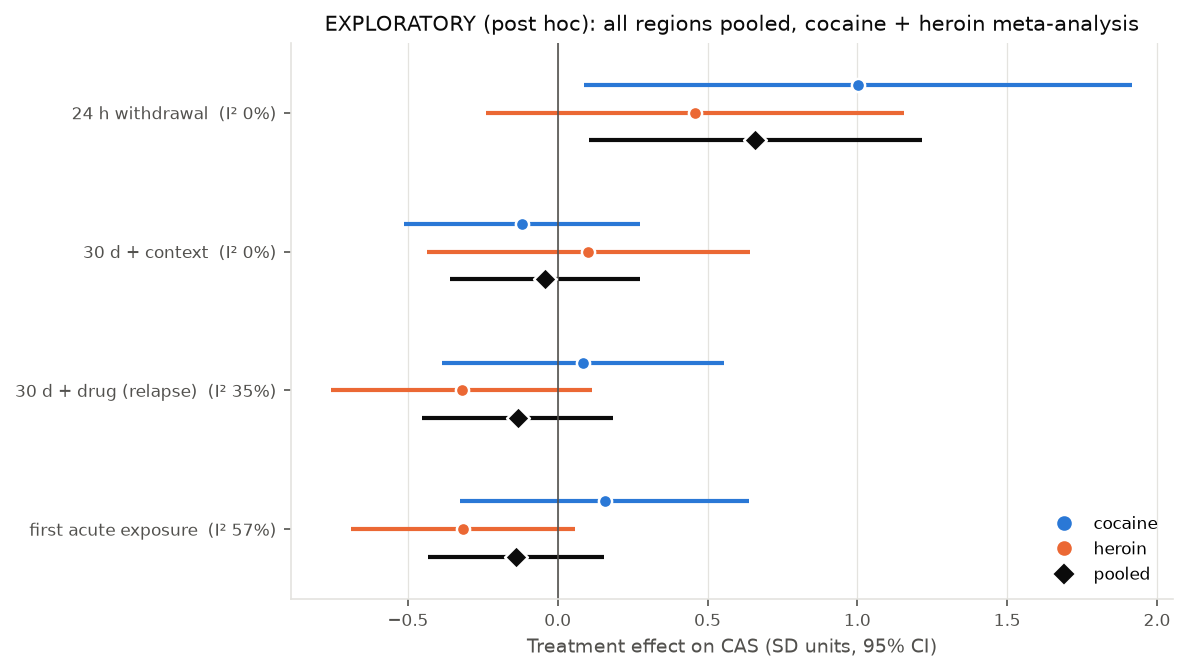

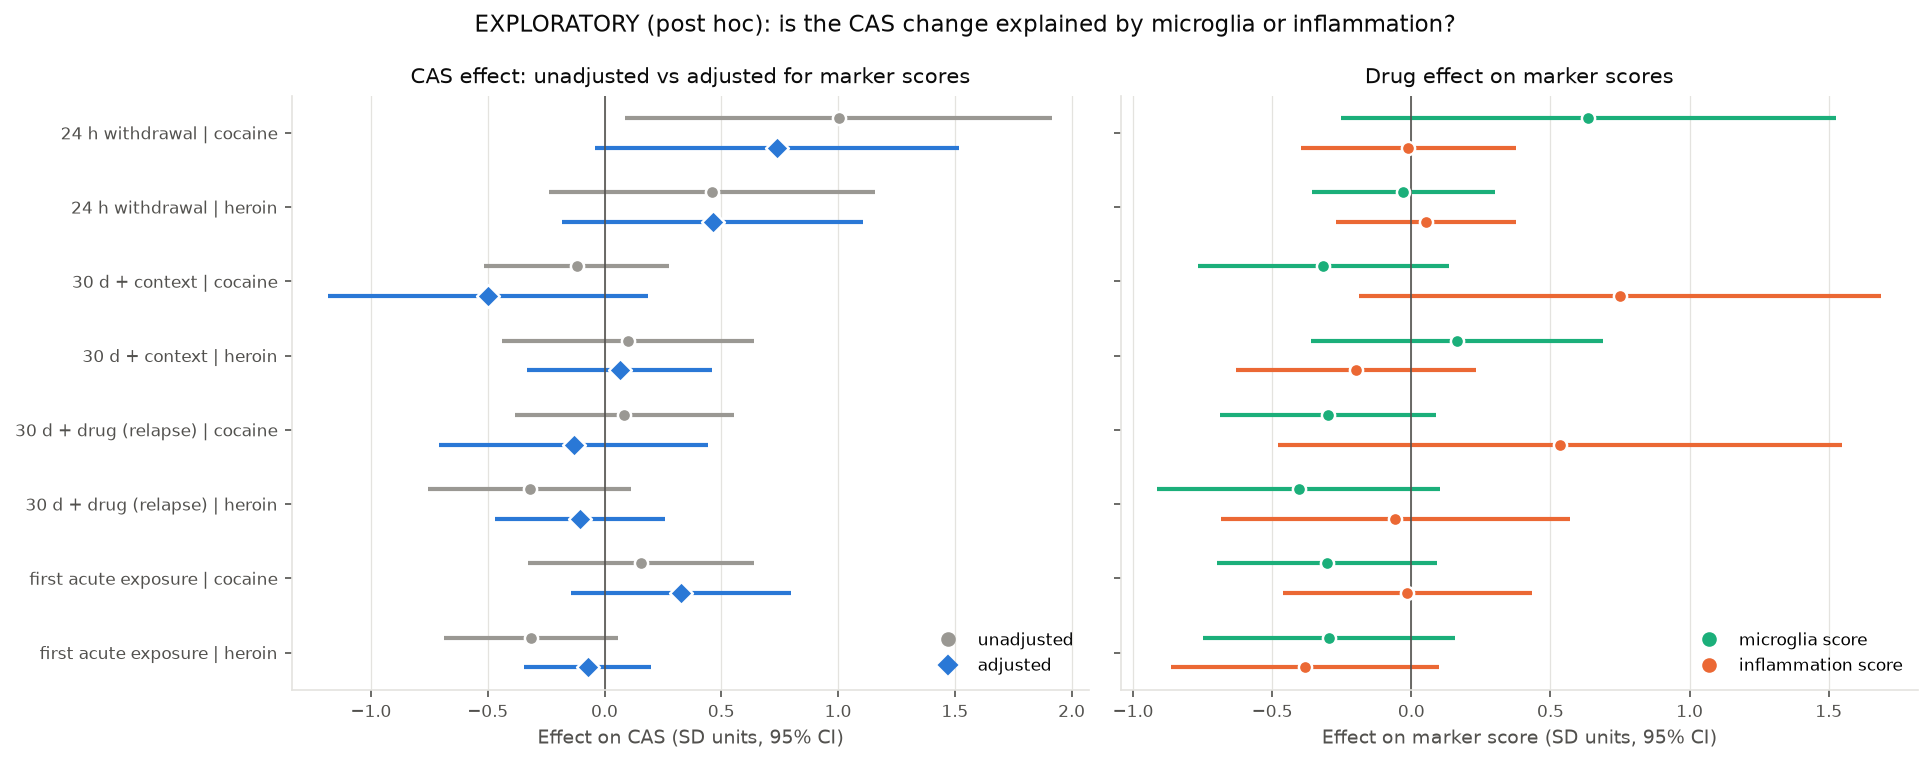

In [4]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
mixed = pd.read_csv(tables / "table_exploratory_mixed_model.csv")
meta = pd.read_csv(tables / "table_exploratory_meta.csv")
spec = pd.read_csv(tables / "table_exploratory_specificity.csv")
for name in ["fig_exploratory_forest.png", "fig_exploratory_specificity.png"]:
    display(Image(figs / name))

In [5]:
mixed[["run", "drug", "design", "n_animals", "estimate", "ci_low", "ci_high", "p", "fdr",
       "region_heterogeneity_p", "converged"]].round(3)

,run,drug,design,n_animals,estimate,ci_low,ci_high,p,fdr,region_heterogeneity_p,converged
0,all,cocaine,24 h withdrawal,16,1.003,0.089,1.918,0.032,0.252,0.272,True
1,all,cocaine,30 d + context,14,-0.120,-0.514,0.275,0.551,0.724,0.002,False
2,all,cocaine,30 d + drug (relapse),15,0.085,-0.385,0.554,0.724,0.724,0.045,True
3,all,cocaine,first acute exposure,16,0.157,-0.326,0.640,0.524,0.724,0.053,True
4,all,heroin,24 h withdrawal,19,0.459,-0.240,1.157,0.198,0.396,0.236,True
5,all,heroin,30 d + context,16,0.102,-0.437,0.641,0.711,0.724,0.294,True
6,all,heroin,30 d + drug (relapse),16,-0.321,-0.756,0.114,0.148,0.395,0.156,True
7,all,heroin,first acute exposure,16,-0.316,-0.688,0.057,0.097,0.387,0.497,True
8,excl_flagged,cocaine,24 h withdrawal,16,0.968,0.070,1.865,0.035,0.277,0.218,True
9,excl_flagged,cocaine,30 d + context,14,-0.108,-0.496,0.281,0.587,0.783,0.003,True


In [6]:
meta[["design", "cocaine_estimate", "heroin_estimate", "fixed_estimate", "fixed_ci_low",
      "fixed_ci_high", "fixed_p", "fixed_fdr", "i2"]].round(3)

,design,cocaine_estimate,heroin_estimate,fixed_estimate,fixed_ci_low,fixed_ci_high,fixed_p,fixed_fdr,i2
0,24 h withdrawal,1.003,0.459,0.659,0.104,1.214,0.020,0.080,0.000
1,30 d + context,-0.120,0.102,-0.043,-0.361,0.276,0.793,0.793,0.000
2,30 d + drug (relapse),0.085,-0.321,-0.134,-0.453,0.185,0.411,0.549,0.352
3,first acute exposure,0.157,-0.316,-0.139,-0.434,0.156,0.355,0.549,0.567


In [7]:
pd.read_csv(tables / "table_exploratory_meta_by_region.csv").round(2)

,analysis,region,design,g_cocaine,g_heroin,g_pooled_fixed,ci_low,ci_high,i2
0,"exploratory (post hoc), descriptive only",BLA,24 h withdrawal,0.22,0.83,0.56,-0.18,1.29,0.00
1,"exploratory (post hoc), descriptive only",BLA,30 d + context,1.03,0.07,0.44,-0.32,1.21,0.31
2,"exploratory (post hoc), descriptive only",BLA,30 d + drug (relapse),0.69,-0.49,0.03,-0.72,0.77,0.58
3,"exploratory (post hoc), descriptive only",BLA,first acute exposure,0.85,-0.60,0.06,-0.67,0.80,0.73
4,"exploratory (post hoc), descriptive only",Cpu,24 h withdrawal,1.04,0.68,0.84,0.15,1.54,0.00
5,"exploratory (post hoc), descriptive only",Cpu,30 d + context,-0.21,0.79,0.32,-0.42,1.07,0.42
6,"exploratory (post hoc), descriptive only",Cpu,30 d + drug (relapse),0.27,-0.19,0.02,-0.70,0.74,0.00
7,"exploratory (post hoc), descriptive only",Cpu,first acute exposure,0.33,-0.20,0.03,-0.70,0.77,0.00
8,"exploratory (post hoc), descriptive only",Hipp,24 h withdrawal,1.01,0.47,0.70,-0.00,1.40,0.00
9,"exploratory (post hoc), descriptive only",Hipp,30 d + context,-2.37,0.13,-0.64,-1.45,0.18,0.87


In [8]:
spec.pivot_table(index=["drug", "design"], columns="model", values="estimate").round(2)

model                          (a) drug effect on inflammation score  \
drug    design                                                         
cocaine 24 h withdrawal                                        -0.01   
        30 d + context                                          0.75   
        30 d + drug (relapse)                                   0.53   
        first acute exposure                                   -0.02   
heroin  24 h withdrawal                                         0.05   
        30 d + context                                         -0.20   
        30 d + drug (relapse)                                  -0.06   
        first acute exposure                                   -0.38   

model                          (a) drug effect on microglia score  \
drug    design                                                      
cocaine 24 h withdrawal                                      0.64   
        30 d + context                                      -0.32   
        30 d + drug (relapse)                               -0.30   
        first acute exposure                                -0.30   
heroin  24 h withdrawal                                     -0.03   
        30 d + context                                       0.16   
        30 d + drug (relapse)                               -0.40   
        first acute exposure                                -0.30   

model                          (b) CAS adjusted for microglia + inflammation  \
drug    design                                                                 
cocaine 24 h withdrawal                                                 0.74   
        30 d + context                                                 -0.50   
        30 d + drug (relapse)                                          -0.13   
        first acute exposure                                            0.33   
heroin  24 h withdrawal                                                 0.46   
        30 d + context                                                  0.06   
        30 d + drug (relapse)                                          -0.10   
        first acute exposure                                           -0.07   

model                          (b) CAS unadjusted (= A)  
drug    design                                           
cocaine 24 h withdrawal                            1.00  
        30 d + context                            -0.12  
        30 d + drug (relapse)                      0.08  
        first acute exposure                       0.16  
heroin  24 h withdrawal                            0.46  
        30 d + context                             0.10  
        30 d + drug (relapse)                     -0.32  
        first acute exposure                      -0.32

In [9]:
pd.read_csv(tables / "table_exploratory_hahn_marker_corr.csv").round(2)

,analysis,region,n,rho_cas_microglia,p_cas_microglia,rho_age_microglia,rho_cas_inflammation,p_cas_inflammation,rho_age_inflammation
0,exploratory (post hoc),cc,57,0.59,0.00,0.43,0.87,0.00,0.81
1,exploratory (post hoc),cer,58,0.70,0.00,0.47,-0.15,0.28,-0.20
2,exploratory (post hoc),cor,59,0.07,0.58,-0.21,-0.08,0.53,-0.09
3,exploratory (post hoc),cp,58,0.69,0.00,0.47,0.48,0.00,0.37
4,exploratory (post hoc),ent,51,0.42,0.00,0.06,0.35,0.01,0.10
5,exploratory (post hoc),hi,57,0.59,0.00,0.49,0.34,0.01,0.37
6,exploratory (post hoc),hi2,58,0.64,0.00,0.46,-0.18,0.18,-0.21
7,exploratory (post hoc),hy,55,0.75,0.00,0.46,0.22,0.11,0.18
8,exploratory (post hoc),med,58,0.84,0.00,0.67,0.86,0.00,0.73
9,exploratory (post hoc),olf,58,0.44,0.00,0.40,0.16,0.23,0.03


In [10]:
genes = pd.read_csv(tables / "table_exploratory_marker_genes.csv")
genes.groupby(["marker_set", "gene"])["used"].mean().unstack(0).round(2)

marker_set,inflammation,microglia
gene,,
Ccl2,0.0,NaN
Ccl3,0.0,NaN
Ccl4,0.0,NaN
Csf1r,NaN,1.0
Cxcl10,0.0,NaN
Fcrls,NaN,1.0
Gpr34,NaN,1.0
Il1b,0.0,NaN
Nfkbia,1.0,NaN


In [11]:
display(pd.read_csv(tables / "table_exploratory_scoring_robustness_summary.csv").round(3))
rob = pd.read_csv(tables / "table_exploratory_scoring_robustness.csv")
rob.query("design == '24 h withdrawal'").pivot_table(
    index=["dataset", "region"], columns="variant", values="g").round(2)

,variant,r_with_current,same_sign,max_abs_diff,all_24h_positive
0,VST instead of log-CPM,0.998,0.958,0.224,True
1,filter >= 1,0.996,0.958,0.167,True
2,filter >= 50,0.989,0.958,0.441,True
3,z-score method (spec),0.872,0.896,1.588,True


variant         VST instead of log-CPM  current  filter >= 1  filter >= 50  \
dataset region                                                               
heroin  BLA                       0.89     0.83         0.88          0.73   
        NAc                       0.94     0.95         0.89          0.94   
        PFC                       0.32     0.31         0.33          0.31   
        VTA                      -0.01     0.00        -0.01         -0.00   
        dStri                     0.69     0.68         0.70          0.72   
        vHPC                      0.48     0.47         0.51          0.42   
walker  BLA                       0.21     0.22         0.21          0.12   
        Cpu                       1.07     1.04         1.06          1.11   
        Hipp                      1.00     1.01         1.03          1.02   
        NAc                       0.99     0.97         0.98          1.01   
        PFC                       1.33     1.26         1.31          1.39   
        VTA                       0.75     0.76         0.78          0.67   

variant         z-score method (spec)  
dataset region                         
heroin  BLA                      0.71  
        NAc                      0.61  
        PFC                      0.45  
        VTA                      0.34  
        dStri                    0.53  
        vHPC                     0.61  
walker  BLA                      0.35  
        Cpu                      1.23  
        Hipp                     1.02  
        NAc                      1.24  
        PFC                      1.71  
        VTA                      0.85